**Nombre:** Jorge Luis González Martínez


# Parte 1. Comparación de modelos de clasificación

En este notebook se trabaja con el dataset de cáncer de mama de Wisconsin, que viene incluido en scikit-learn. La idea es clasificar si un tumor es maligno o benigno a partir de 30 medidas que se tomaron de los núcleos de las células en imágenes de biopsias.

En la variable objetivo (`target`), el 0 es maligno y el 1 es benigno. Como lo que más interesa es detectar los tumores malignos, la precisión, el recall y el F1 se calculan pensando en la clase maligna (por eso en el código aparece `pos_label=0`).

## 1. Exploración de los datos

Primero se carga el dataset como tabla de pandas y se revisa su información general.

In [1]:
import pandas as pd 
from sklearn.datasets import load_breast_cancer

df = load_breast_cancer(as_frame=True).frame

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

el conjunto tiene **569 registros** (pacientes) y **31 columnas**: 30 variables numéricas (`float64`) y la variable objetivo `target` (`int64`). Ninguna columna tiene valores faltantes (569 *non-null* en todas).

Las 30 variables son **10 medidas** del núcleo celular, cada una resumida de **3 formas**:

| Medida | Qué describe |
|---|---|
| radius / perimeter / area | Tamaño del núcleo |
| texture | Variación de tonos de gris dentro del núcleo |
| smoothness | Qué tan liso es el contorno |
| compactness | Qué tanto se aleja la forma de un círculo |
| concavity / concave points | Profundidad y número de partes hundidas del contorno |
| symmetry | Simetría del núcleo |
| fractal dimension | Complejidad o "rugosidad" del borde |

| Prefijo / sufijo | Significado |
|---|---|
| `mean ...` | Promedio de todos los núcleos de la imagen |
| `... error` | Error estándar (qué tanto varían los núcleos entre sí) |
| `worst ...` | Promedio de los 3 núcleos con los valores más altos |

In [2]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df["target"].value_counts()

df["target"].value_counts(normalize=True)

target
1    0.627417
0    0.372583
Name: proportion, dtype: float64

Hay 357 casos benignos (63 %) y 212 malignos (37 %), o sea, las clases no están parejas pero el desbalance es leve.

Esto es importante porque un modelo que dijera "benigno" a todos acertaría el 63 % de las veces sin detectar ningún cáncer. Por eso más adelante no se evalúa solo con el accuracy, y al dividir los datos se cuida que cada conjunto tenga la misma proporción de clases.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


De la estadística descriptiva se ven varias cosas. La primera es que las variables están en escalas muy diferentes: el área promedio anda cerca de 655, mientras que la suavidad promedio es de 0.096. Esto afecta a modelos como la regresión logística o la SVM, así que habrá que escalar los datos antes de entrenar.

También hay valores muy alejados del resto. Por ejemplo, en `area error` el 75 % de los pacientes está por debajo de 45, pero el máximo es 542. Además, en varias variables la media es mayor que la mediana (en `mean area` es 654.9 contra 551.1), lo que indica que unos cuantos valores grandes jalan el promedio hacia arriba. Los ceros que aparecen en concavidad y puntos cóncavos no son errores, son núcleos con el borde completamente liso.

In [5]:
print(load_breast_cancer().DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

### Casos por diagnóstico

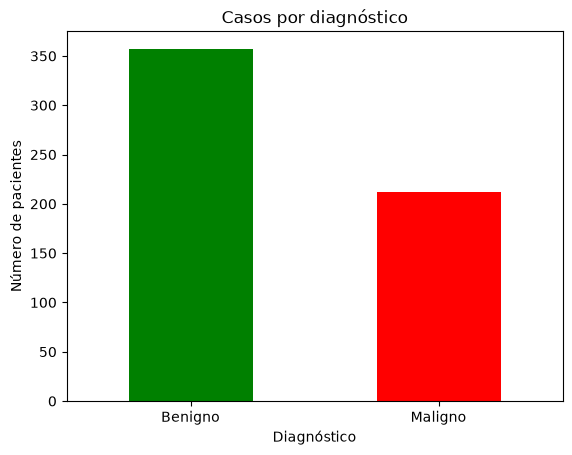

In [ ]:
import matplotlib.pyplot as plt

conteo = df["target"].value_counts()
conteo = conteo.rename({0: "Maligno", 1: "Benigno"})

conteo.plot(kind="bar", rot=0, color=["green", "red"])

plt.title("Casos por diagnóstico")
plt.xlabel("Diagnóstico")
plt.ylabel("Número de pacientes")
plt.show()

### Distribución de las variables

Para las gráficas se usan solo las 10 variables `mean`, porque las versiones `error` y `worst` describen las mismas características y con 30 gráficas sería difícil leer algo.

In [14]:
import seaborn as sns

columnas = list(df.columns[:10])
columnas

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean concave points',
 'mean symmetry',
 'mean fractal dimension']

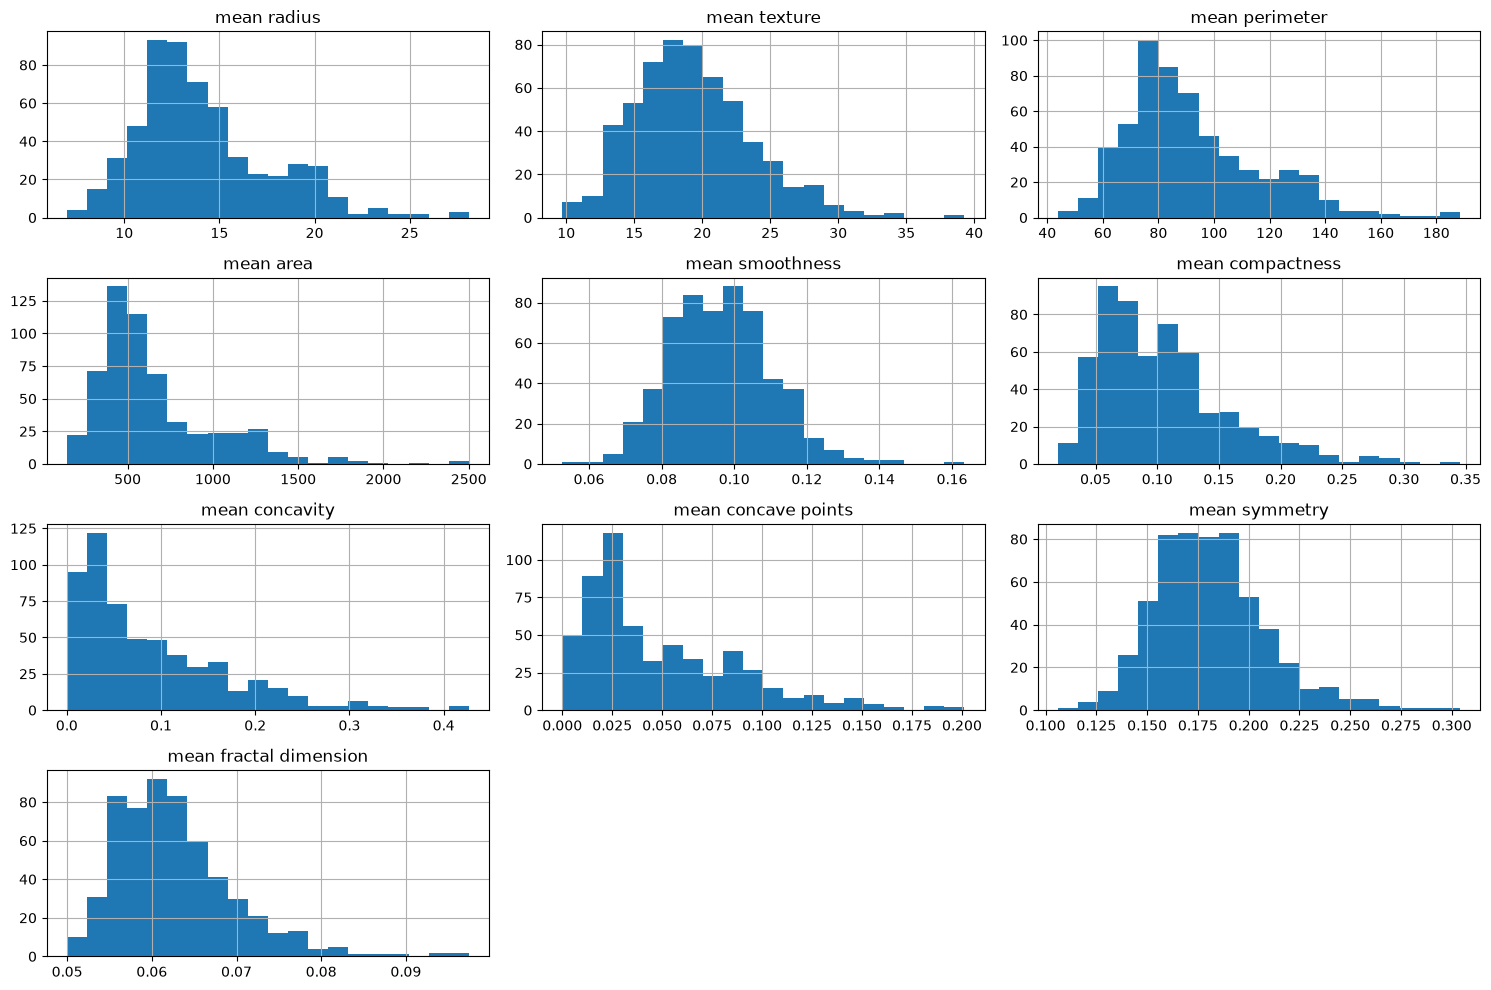

In [17]:
df[columnas].hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

La textura, la suavidad y la simetría tienen una forma parecida a una campana. El resto de las variables tienen una cola larga hacia la derecha, sobre todo el área, la concavidad y los puntos cóncavos: la mayoría de los pacientes tiene valores bajos y solo unos pocos tienen valores muy altos.

En el radio, el perímetro y el área se alcanza a ver un segundo "bultito" en valores altos. Eso hace pensar que hay dos grupos con tamaños distintos, lo cual se confirma después con los boxplots.

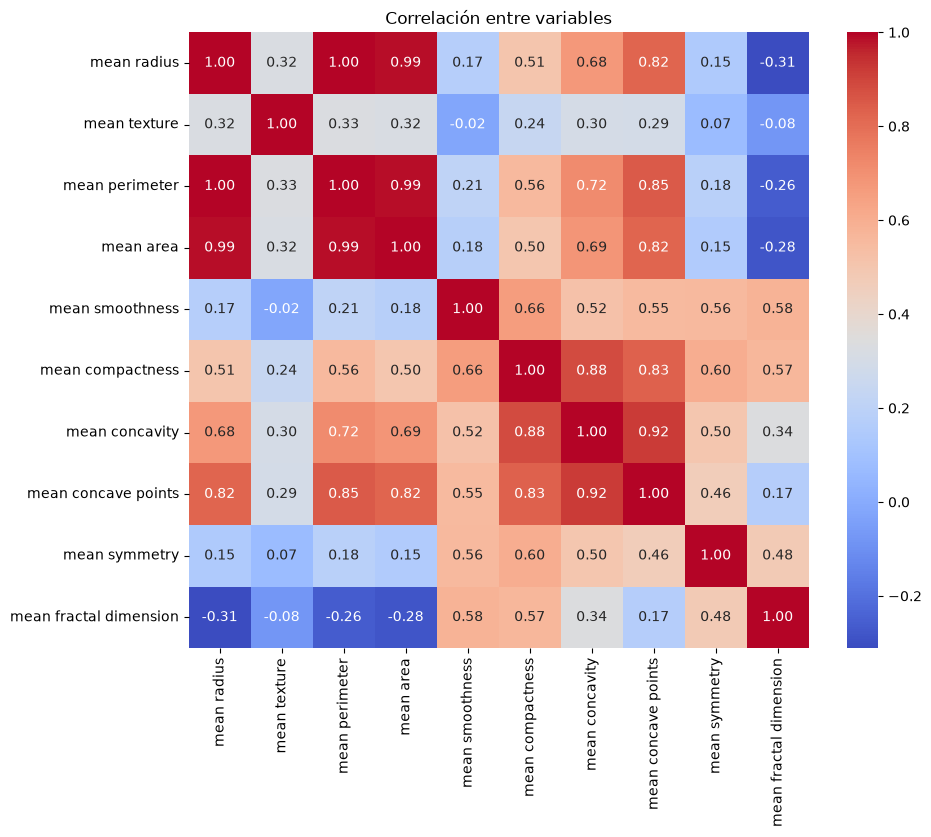

In [19]:
correlacion = df[columnas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación entre variables")
plt.show()

El radio, el perímetro y el área tienen una correlación casi de 1 entre ellas, lo cual tiene sentido porque las tres miden el tamaño del núcleo; en la práctica dan información repetida. La compacidad, la concavidad y los puntos cóncavos también están muy relacionadas (entre 0.83 y 0.92), ya que las tres tienen que ver con qué tan irregular es la forma. La textura casi no se relaciona con las demás, así que aporta información diferente.

### Boxplots por diagnóstico

En rojo están los malignos (0) y en verde los benignos (1). Cada gráfica tiene su propio eje porque, si comparten el mismo, el área (que llega a 2,500) deja aplastadas a todas las demás.

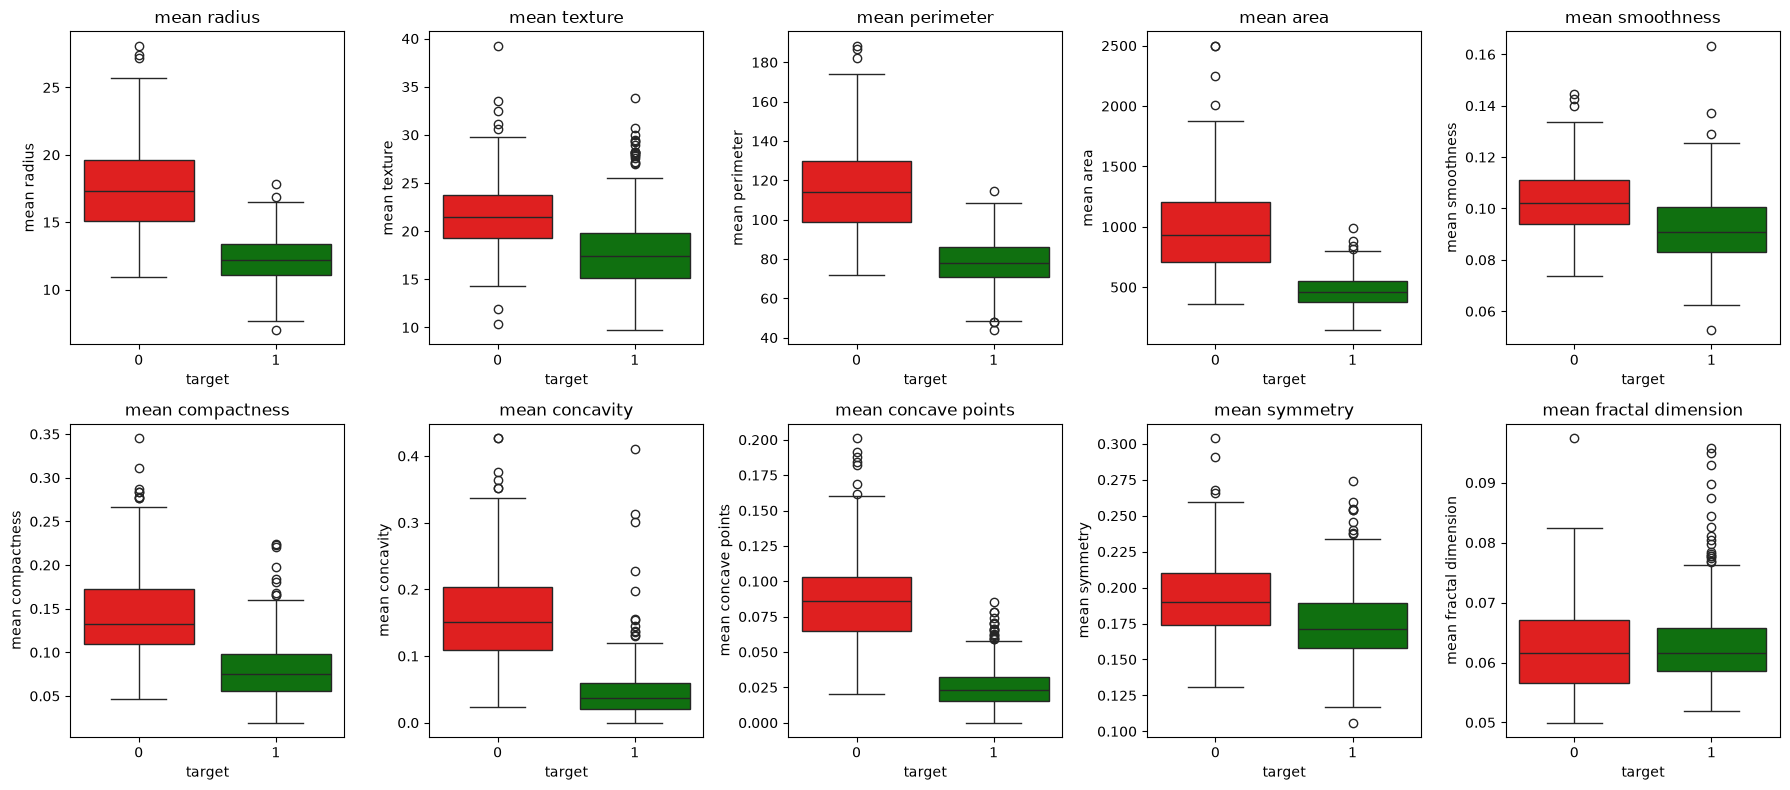

In [20]:
plt.figure(figsize=(18, 8))
numero = 1

for col in columnas:
    plt.subplot(2, 5, numero)
    sns.boxplot(data=df, x="target", y=col, hue="target", palette=["red", "green"], legend=False)
    plt.title(col)
    numero = numero + 1

plt.tight_layout()
plt.show()

La forma de ver si una variable sirve para distinguir las clases es fijarse si las cajas de rojo y verde quedan a distinta altura. En los puntos cóncavos, el radio, el perímetro, el área, la concavidad y la compacidad las cajas casi no se enciman: los tumores malignos tienen núcleos más grandes y con bordes más irregulares. La que mejor separa es `mean concave points`.

En la textura, la suavidad y la simetría las cajas se enciman en parte, así que ayudan pero no son suficientes solas. En la dimensión fractal las dos medianas están casi a la misma altura, por lo que no sirve para distinguir.

También se nota que las cajas verdes son más chicas, es decir, los benignos se parecen más entre sí. Los puntos sueltos son datos atípicos; los benignos con valores altos de concavidad probablemente serán los casos más difíciles para el modelo.

Como varias variables separan tan bien las clases, se espera que incluso un modelo lineal funcione bien.

### Revisión de la calidad de los datos

In [21]:
df.isnull().sum().sum()

np.int64(0)

In [22]:
df.duplicated().sum()

np.int64(0)

No hay valores vacíos ni registros repetidos, todas las variables son numéricas y el diagnóstico ya viene como 0 y 1, así que no hubo que limpiar ni convertir nada.

Los valores atípicos se dejaron como están. Son datos médicos y un tumor muy grande puede ser real, no un error. Además, la mayoría aparecen en los malignos, que son justo los casos que el modelo tiene que aprender a reconocer, y quitar registros en un dataset tan chico no tiene mucho sentido.

## 2. División de los datos y escalado

Los 569 registros se reparten en tres conjuntos: 60 % para entrenamiento (341), 20 % para validación (114) y 20 % para prueba (114). Cada paciente queda en un solo conjunto.

El de entrenamiento es con el que el modelo aprende, y también se usa para la validación cruzada al ajustar hiperparámetros. El de validación sirve para comparar los modelos y escoger el mejor. El de prueba se guarda hasta el final y se usa una sola vez, para ver qué tan bien funciona el modelo elegido con pacientes que nunca vio.

No se evalúa con los mismos datos de entrenamiento porque así no se puede saber si el modelo aprendió o solo memorizó. Y la prueba se usa una sola vez porque si se usara para tomar decisiones, el modelo terminaría acomodado a esos datos y su calificación ya no sería honesta.

Se eligió 60/20/20 porque el dataset es pequeño, y así validación y prueba quedan con unos 42 malignos cada uno, suficientes para que un solo error no mueva tanto las métricas. La división se hace con `stratify` para que los tres conjuntos tengan la misma proporción de malignos y benignos, y con `random_state=42` para que siempre salga igual.

In [23]:
X = df.drop(columns="target")
y = df["target"]

print("X:", X.shape)
print("y:", y.shape)

X: (569, 30)
y: (569,)


In [24]:
from sklearn.model_selection import train_test_split

# Primer corte: apartar 20 % para prueba
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Segundo corte: del 80 % restante, apartar 25 % para validación (= 20 % del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

In [25]:
print("Entrenamiento:", X_train.shape)
print("Validación:   ", X_val.shape)
print("Prueba:       ", X_test.shape)

Entrenamiento: (341, 30)
Validación:    (114, 30)
Prueba:        (114, 30)


In [26]:
print("Entrenamiento:\n", y_train.value_counts(normalize=True).round(2))
print("Validación:\n", y_val.value_counts(normalize=True).round(2))
print("Prueba:\n", y_test.value_counts(normalize=True).round(2))

Entrenamiento:
 target
1    0.63
0    0.37
Name: proportion, dtype: float64
Validación:
 target
1    0.62
0    0.38
Name: proportion, dtype: float64
Prueba:
 target
1    0.63
0    0.37
Name: proportion, dtype: float64


Los tres conjuntos quedaron con la misma proporción que el dataset original (alrededor de 63 % benignos y 37 % malignos).

### Escalado

Para que todas las variables estén en la misma escala se usa `StandardScaler`, que a cada valor le resta la media de su columna y lo divide entre la desviación estándar:

$$z = \frac{x - \mu}{\sigma}$$

Con esto, cada valor indica qué tan arriba o abajo del promedio está, y todas las columnas quedan con media 0 y desviación 1.

La media y la desviación se calculan solo con el conjunto de entrenamiento (`fit`) y luego se aplican igual a los tres conjuntos (`transform`). Si se calcularan con todos los datos, información de validación y prueba se colaría al entrenamiento, lo que se conoce como fuga de información (*data leakage*), y los resultados saldrían más optimistas de lo que son. Además, en la vida real los pacientes nuevos llegan de uno en uno y hay que escalarlos con algo que ya se conoce.

In [27]:
from sklearn.preprocessing import StandardScaler

# Crear el escalador (libreta vacía)
escalador = StandardScaler()

# FIT: aprender promedio y desviación SOLO con entrenamiento
escalador.fit(X_train)

# TRANSFORM: convertir los tres conjuntos con la misma libreta
X_train_esc = escalador.transform(X_train)
X_val_esc = escalador.transform(X_val)
X_test_esc = escalador.transform(X_test)

In [28]:
print("Promedio entrenamiento:", X_train_esc.mean().round(2))
print("Desviación entrenamiento:", X_train_esc.std().round(2))
print("Promedio prueba:", X_test_esc.mean().round(2))

Promedio entrenamiento: -0.0
Desviación entrenamiento: 1.0
Promedio prueba: 0.01


En entrenamiento la media salió 0 y la desviación 1. En prueba la media salió 0.01, cerca de 0 pero no exacta, lo que confirma que se escaló con los valores del entrenamiento.

## 3. Entrenamiento de los modelos

Además de la regresión logística, que era obligatoria, se eligieron una SVM y un Random Forest. La idea fue tener tres modelos que funcionan de forma muy distinta para poder compararlos.

La regresión logística es sencilla, fácil de interpretar y da probabilidades, lo cual es útil en un problema médico. La SVM funciona bien cuando hay muchas variables, como aquí, y con un kernel puede trazar fronteras curvas. El Random Forest aguanta bien los valores atípicos y las variables muy correlacionadas (como radio, perímetro y área), que son justo cosas que tiene este dataset, y además dice qué variables fueron las más importantes.

En esta sección se entrenan con sus valores por defecto. En la sección 4 se ajustan sus hiperparámetros.

### 3.1 Regresión logística

La regresión logística primero calcula una suma de las variables multiplicadas por unos pesos:

$$z = b + w_1x_1 + w_2x_2 + \dots + w_{30}x_{30}$$

Ese valor $z$ puede ser cualquier número, así que se pasa por la función sigmoide, que lo convierte en una probabilidad entre 0 y 1:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Si la probabilidad pasa de 0.5 se asigna una clase y si no, la otra. Cada coeficiente $w$ indica qué tanto empuja esa variable hacia una clase: si es negativo, mientras más grande sea la variable, menos probable es que el tumor sea benigno. Los pesos los aprende el modelo durante el entrenamiento.

Conviene escalar los datos porque la regularización castiga los pesos grandes, y el tamaño de los pesos depende de la escala de cada variable. Su ventaja es que es simple, rápida y fácil de explicar; su desventaja es que solo puede trazar fronteras rectas.

In [29]:

from sklearn.linear_model import LogisticRegression

modelo_lr = LogisticRegression(max_iter=1000, random_state=42)

In [30]:
modelo_lr.fit(X_train_esc, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

En los atributos aprendidos, `coef_` son los 30 pesos de la ecuación e `intercept_` es el valor de $b$. Los pesos de las variables de tamaño salieron negativos, lo que cuadra con los boxplots: núcleos más grandes, menos probabilidad de ser benigno.

In [31]:
pred_train_lr = modelo_lr.predict(X_train_esc)
pred_val_lr = modelo_lr.predict(X_val_esc)

In [32]:
from sklearn.metrics import accuracy_score

print("Exactitud entrenamiento:", round(accuracy_score(y_train, pred_train_lr), 3))
print("Exactitud validación:   ", round(accuracy_score(y_val, pred_val_lr), 3))

Exactitud entrenamiento: 0.988
Exactitud validación:    0.991


In [33]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_val, pred_val_lr))

[[42  1]
 [ 0 71]]


In [34]:
from sklearn.metrics import classification_report

print(classification_report(y_val, pred_val_lr, target_names=["Maligno", "Benigno"]))

              precision    recall  f1-score   support

     Maligno       1.00      0.98      0.99        43
     Benigno       0.99      1.00      0.99        71

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



Con los valores por defecto (C = 1), el modelo tuvo 98.8 % de accuracy en entrenamiento y 99.1 % en validación. Como son casi iguales, no hay señal de que haya memorizado. En validación detectó 42 de los 43 malignos y no dio ninguna falsa alarma.

### 3.2 SVM

La SVM busca la frontera que separa las dos clases dejando el "camino" más ancho posible entre ellas (el margen). Solo los puntos que quedan en la orilla de ese camino, llamados vectores de soporte, definen la frontera; los demás no influyen. Con el kernel RBF la frontera puede ser curva cuando una línea recta no alcanza.

Se usa mucho en problemas con muchas variables y no tantos datos. Necesita que los datos estén escalados porque trabaja con distancias entre puntos. Sus ventajas son que funciona bien en muchas dimensiones y es flexible gracias al kernel; sus desventajas son que se vuelve lenta con muchos datos, depende mucho de elegir bien C y gamma, y es difícil de interpretar.

In [35]:
from sklearn.svm import SVC

modelo_svm = SVC(kernel="rbf", C=1.0, random_state=42)

In [36]:
modelo_svm.fit(X_train_esc, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


La frontera quedó definida por 85 vectores de soporte (44 malignos y 41 benignos), alrededor del 25 % de los datos de entrenamiento.

In [37]:
pred_train_svm = modelo_svm.predict(X_train_esc)
pred_val_svm = modelo_svm.predict(X_val_esc)

In [38]:
print("Exactitud entrenamiento:", round(accuracy_score(y_train, pred_train_svm), 3))
print("Exactitud validación:   ", round(accuracy_score(y_val, pred_val_svm), 3))

Exactitud entrenamiento: 0.982
Exactitud validación:    0.982


In [39]:
print(confusion_matrix(y_val, pred_val_svm))

[[41  2]
 [ 0 71]]


In [40]:
print(classification_report(y_val, pred_val_svm, target_names=["Maligno", "Benigno"]))

              precision    recall  f1-score   support

     Maligno       1.00      0.95      0.98        43
     Benigno       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Con los valores por defecto, la SVM tuvo 98.2 % de accuracy tanto en entrenamiento como en validación. En validación detectó 41 de 43 malignos, sin falsas alarmas.

### 3.3 Random Forest

El Random Forest es un conjunto de muchos árboles de decisión (aquí 100). Cada árbol aprende con una muestra al azar de pacientes y, en cada pregunta, solo puede escoger entre unas cuantas variables al azar (alrededor de 5 de las 30). Al final, los árboles votan y gana la clase con más votos. Como cada árbol es un poco diferente, sus errores tienden a compensarse y el resultado es más estable que con un solo árbol.

Sirve para datos en tabla, tanto en clasificación como en regresión, y no necesita escalar los datos porque los árboles solo hacen preguntas del tipo "¿el área es mayor a 700?". Aun así, se le pasaron los mismos datos que a los otros modelos para compararlos en igualdad de condiciones. Sus ventajas son que aguanta bien los atípicos y las variables correlacionadas y que indica qué variables importan más; sus desventajas son que es menos interpretable, más pesado y tiende a ajustarse mucho al entrenamiento.

In [41]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)

In [42]:
modelo_rf.fit(X_train_esc, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [43]:
pred_train_rf = modelo_rf.predict(X_train_esc)
pred_val_rf = modelo_rf.predict(X_val_esc)

In [44]:
print("Exactitud entrenamiento:", round(accuracy_score(y_train, pred_train_rf), 3))
print("Exactitud validación:   ", round(accuracy_score(y_val, pred_val_rf), 3))

Exactitud entrenamiento: 1.0
Exactitud validación:    0.956


In [45]:
print(confusion_matrix(y_val, pred_val_rf))

[[40  3]
 [ 2 69]]


In [46]:
print(classification_report(y_val, pred_val_rf, target_names=["Maligno", "Benigno"]))

              precision    recall  f1-score   support

     Maligno       0.95      0.93      0.94        43
     Benigno       0.96      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Con los valores por defecto obtuvo 100 % en entrenamiento y 95.6 % en validación. Que salga 100 % en entrenamiento es normal en un Random Forest; lo que importa es la validación. Detectó 40 de 43 malignos y dio 2 falsas alarmas.

In [47]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(10)

worst concave points    0.181774
worst area              0.142437
mean concave points     0.096680
worst perimeter         0.080248
mean concavity          0.071406
mean area               0.051357
mean perimeter          0.051354
worst radius            0.049882
mean radius             0.041090
area error              0.034336
dtype: float64

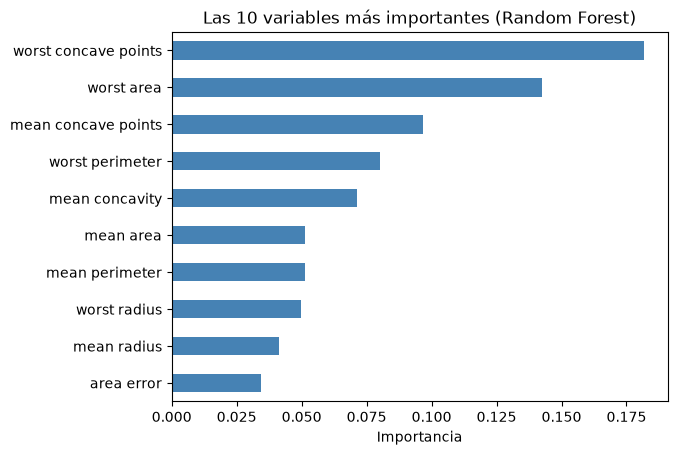

In [48]:
importancias.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Las 10 variables más importantes (Random Forest)")
plt.xlabel("Importancia")
plt.show()

Las variables más importantes fueron `worst concave points`, `worst area` y `mean concave points`, seguidas de otras de tamaño y concavidad. Esto coincide con los boxplots, donde estas eran las variables cuyas cajas no se enciman. La importancia del radio, perímetro y área se reparte entre las tres porque miden prácticamente lo mismo.

## 4. Ajuste de hiperparámetros con validación cruzada

Los parámetros son lo que el modelo aprende solo con los datos, como los pesos de la regresión logística. Los hiperparámetros, en cambio, se eligen antes de entrenar y controlan cómo aprende el modelo, por ejemplo C o la profundidad de los árboles. Hasta ahora se habían usado los valores por defecto, pero nada asegura que sean los mejores para este problema.

Para encontrarlos se usó validación cruzada de 5 partes sobre el conjunto de entrenamiento: se divide en 5 pedazos, se entrena con 4 y se evalúa con el que sobra, y esto se repite 5 veces rotando el pedazo que se deja fuera. Al final se promedian las 5 calificaciones. Así la estimación es más confiable que con una sola división y no se tocan los conjuntos de validación ni de prueba. `GridSearchCV` hace esto para cada valor que se quiere probar y se queda con el mejor.

Como métrica se usó el F1 de la clase maligna. No se usó solo el recall porque un modelo que dijera "maligno" a todos tendría recall perfecto y sería inútil; el F1 toma en cuenta también la precisión.

Para no tener fuga de información dentro de la validación cruzada, el escalador y el modelo se juntaron en un `Pipeline` y se le pasaron los datos sin escalar. Así, en cada vuelta, el escalador se ajusta solo con los pedazos de entrenamiento.

### 4.1 Regresión logística

In [49]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

In [50]:
f1_maligno = make_scorer(f1_score, pos_label=0)

In [51]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [52]:
pipe_lr = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=42))
])

In [53]:
rejilla_lr = {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100]}

In [54]:
busqueda_lr = GridSearchCV(
    pipe_lr,
    rejilla_lr,
    cv=cv,
    scoring=f1_maligno,
    return_train_score=True
)

busqueda_lr.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f..., pos_label=0)"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be dete

In [55]:
print("Mejor C:", busqueda_lr.best_params_)
print("F1 maligno promedio (validación cruzada):", round(busqueda_lr.best_score_, 3))

Mejor C: {'modelo__C': 0.1}
F1 maligno promedio (validación cruzada): 0.972


In [56]:
resultados_lr = pd.DataFrame(busqueda_lr.cv_results_)
resultados_lr[["param_modelo__C", "mean_train_score", "mean_test_score"]].round(3)

,param_modelo__C,mean_train_score,mean_test_score
0,0.001,0.799,0.798
1,0.010,0.933,0.932
2,0.100,0.978,0.972
3,1.000,0.984,0.953
4,10.000,0.989,0.938
5,100.000,1.000,0.930


In [57]:
modelo_lr_aj = busqueda_lr.best_estimator_

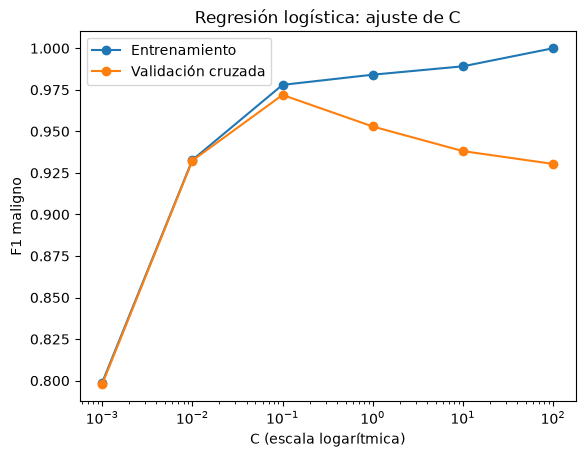

In [58]:
plt.plot(resultados_lr["param_modelo__C"], resultados_lr["mean_train_score"], marker="o", label="Entrenamiento")
plt.plot(resultados_lr["param_modelo__C"], resultados_lr["mean_test_score"], marker="o", label="Validación cruzada")
plt.xscale("log")
plt.xlabel("C (escala logarítmica)")
plt.ylabel("F1 maligno")
plt.title("Regresión logística: ajuste de C")
plt.legend()
plt.show()

El hiperparámetro C controla la regularización, es decir, qué tanto se castiga que los pesos sean grandes. En scikit-learn funciona al revés que λ: con C chico la regularización es fuerte y el modelo queda más simple, y con C grande es débil y el modelo puede memorizar.

El mejor valor fue C = 0.1, con un F1 promedio de 0.972, mejor que el valor por defecto (C = 1). En la gráfica se ve bien la idea de sesgo y varianza: con C = 0.001 el F1 está en 0.80 tanto en entrenamiento como en validación, o sea, el modelo no aprende (subajuste). Conforme C crece, el entrenamiento siempre mejora, pero la validación sube hasta C = 0.1 y luego baja. Con C = 100 el entrenamiento llega a 1.00 y la validación cae a 0.93, que es sobreajuste.

### 4.2 SVM

In [59]:
pipe_svm = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", SVC(kernel="rbf", random_state=42))
])

In [60]:
rejilla_svm = {
    "modelo__C": [0.1, 1, 10, 100],
    "modelo__gamma": [0.001, 0.01, 0.1, 1]
}

In [61]:
busqueda_svm = GridSearchCV(
    pipe_svm,
    rejilla_svm,
    cv=cv,
    scoring=f1_maligno,
    return_train_score=True
)

busqueda_svm.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__C': [0.1, 1, ...], 'modelo__gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f..., pos_label=0)"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is 

In [62]:
print("Mejores hiperparámetros:", busqueda_svm.best_params_)
print("F1 maligno promedio (validación cruzada):", round(busqueda_svm.best_score_, 3))


resultados_svm = pd.DataFrame(busqueda_svm.cv_results_)
columnas_svm = ["param_modelo__C", "param_modelo__gamma", "mean_train_score", "mean_test_score"]
resultados_svm[columnas_svm].sort_values("mean_test_score", ascending=False).round(3)

Mejores hiperparámetros: {'modelo__C': 10, 'modelo__gamma': 0.001}
F1 maligno promedio (validación cruzada): 0.967


,param_modelo__C,param_modelo__gamma,mean_train_score,mean_test_score
8,10.0,0.001,0.971,0.967
9,10.0,0.010,0.984,0.964
12,100.0,0.001,0.980,0.952
5,1.0,0.010,0.971,0.950
13,100.0,0.010,0.998,0.943
6,1.0,0.100,0.987,0.942
10,10.0,0.100,1.000,0.924
14,100.0,0.100,1.000,0.924
4,1.0,0.001,0.925,0.923
1,0.1,0.010,0.927,0.919


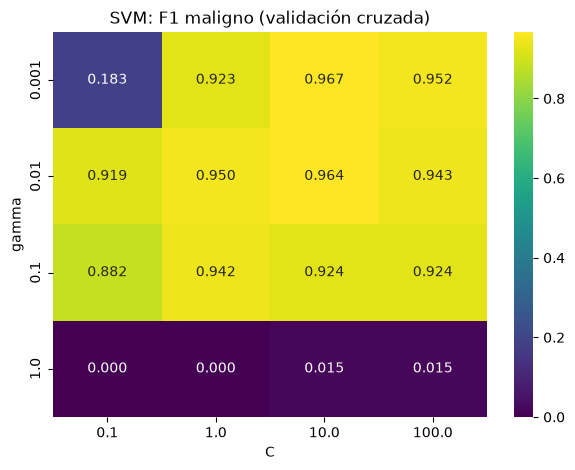

In [63]:
tabla_calor = resultados_svm.pivot_table(
    index="param_modelo__gamma",
    columns="param_modelo__C",
    values="mean_test_score"
)

plt.figure(figsize=(7, 5))
sns.heatmap(tabla_calor, annot=True, fmt=".3f", cmap="viridis")
plt.title("SVM: F1 maligno (validación cruzada)")
plt.xlabel("C")
plt.ylabel("gamma")
plt.show()

In [64]:
modelo_svm_aj = busqueda_svm.best_estimator_

En la SVM se ajustaron dos hiperparámetros. C controla qué tanto tolera errores: con C chico el margen es más ancho y tolerante, y con C grande el modelo intenta no equivocarse en nada y puede memorizar. Gamma controla qué tan lejos llega la influencia de cada punto: con gamma chico la frontera es suave, casi recta, y con gamma grande la frontera se vuelve muy irregular y rodea a cada punto.

La mejor combinación fue C = 10 y gamma = 0.001, con un F1 de 0.967 en validación cruzada y 0.971 en entrenamiento, así que no hay sobreajuste. En el mapa de calor se ve que con gamma = 1 el modelo se desploma: en entrenamiento saca 1.00 pero en validación casi 0, porque memorizó cada punto y a los pacientes nuevos les dice "benigno". En la esquina de C = 0.1 y gamma = 0.001 pasa lo contrario, la frontera es tan simple que no aprende.

Que el mejor gamma haya sido el más chico indica que una frontera casi recta es suficiente para este problema.

### 4.3 Random Forest

In [65]:
modelo_rf_base = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

In [66]:
rejilla_rf = {
    "max_depth": [2, 4, 8, 16],
    "min_samples_leaf": [1, 3, 5, 10]
}

In [67]:
busqueda_rf = GridSearchCV(
    modelo_rf_base,
    rejilla_rf,
    cv=cv,
    scoring=f1_maligno,
    return_train_score=True
)

busqueda_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 4, ...], 'min_samples_leaf': [1, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f..., pos_label=0)"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set an

In [70]:
print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print("F1 maligno promedio (validación cruzada):", round(busqueda_rf.best_score_, 3))


resultados_rf = pd.DataFrame(busqueda_rf.cv_results_)
columnas_rf = ["param_max_depth", "param_min_samples_leaf", "mean_train_score", "mean_test_score"]
resultados_rf[columnas_rf].sort_values("mean_test_score", ascending=False).round(3)





Mejores hiperparámetros: {'max_depth': 8, 'min_samples_leaf': 3}
F1 maligno promedio (validación cruzada): 0.96


,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score
13,16,3,0.991,0.960
9,8,3,0.991,0.960
8,8,1,1.000,0.956
12,16,1,1.000,0.956
4,4,1,0.992,0.951
14,16,5,0.980,0.939
10,8,5,0.980,0.939
5,4,3,0.989,0.935
1,2,3,0.960,0.931
0,2,1,0.959,0.931


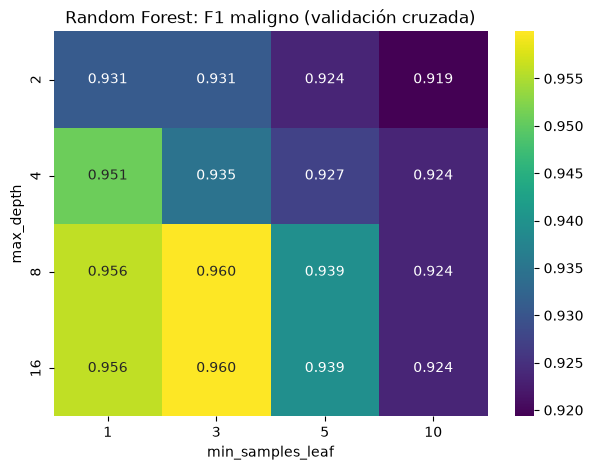

In [71]:
tabla_calor_rf = resultados_rf.pivot_table(
    index="param_max_depth",
    columns="param_min_samples_leaf",
    values="mean_test_score"
)

plt.figure(figsize=(7, 5))
sns.heatmap(tabla_calor_rf, annot=True, fmt=".3f", cmap="viridis")
plt.title("Random Forest: F1 maligno (validación cruzada)")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.show()

In [69]:
modelo_rf_aj = busqueda_rf.best_estimator_

En el Random Forest se ajustaron `max_depth`, que es cuántas preguntas seguidas puede hacer cada árbol, y `min_samples_leaf`, que es el mínimo de pacientes que debe haber en cada hoja (el final de un camino de preguntas). Árboles muy chaparros o con hojas muy grandes dan reglas demasiado simples; árboles muy profundos con hojas de un solo paciente pueden memorizar.

La mejor combinación fue `max_depth` = 8 y `min_samples_leaf` = 3, con un F1 de 0.960 en validación cruzada y 0.991 en entrenamiento. Todas las combinaciones dieron resultados entre 0.92 y 0.96, así que el Random Forest es bastante estable. Con hojas de 1 paciente el entrenamiento llega a 1.00 pero la validación baja a 0.956, lo que muestra que limitar las hojas funciona como regularización. Las profundidades 8 y 16 dieron exactamente lo mismo porque los árboles nunca necesitan más de 8 niveles con estos datos.

Después del ajuste, el orden quedó igual que con los modelos base: regresión logística (0.972), SVM (0.967) y Random Forest (0.960).

## 5. Evaluación en entrenamiento y validación

Ahora se evalúan los tres modelos ya ajustados. Las métricas se calculan tomando a los malignos como clase positiva. El accuracy es el porcentaje total de aciertos. La precisión dice, de los casos que el modelo llamó malignos, cuántos sí lo eran. El recall dice, de todos los malignos reales, cuántos detectó. El F1 combina precisión y recall en un solo número.

Para la curva ROC, en lugar de usar directamente la predicción se usa el puntaje de sospecha de que el tumor sea maligno (la probabilidad, o en la SVM la distancia a la frontera). La curva prueba todos los umbrales posibles y grafica el recall contra la tasa de falsas alarmas. Mientras más pegada esté a la esquina de arriba a la izquierda, mejor. El AUC es el área bajo esa curva: 1 es perfecto y 0.5 es como adivinar. Se puede ver como la probabilidad de que el modelo le dé más sospecha a un maligno que a un benigno tomados al azar. Como solo importa el orden de los puntajes, se pueden comparar los AUC de los tres modelos aunque sus puntajes estén en escalas distintas.

In [72]:
from sklearn.metrics import precision_score, recall_score, roc_curve, auc

In [73]:
pred_lr_train = modelo_lr_aj.predict(X_train)
pred_lr_val = modelo_lr_aj.predict(X_val)

pred_svm_train = modelo_svm_aj.predict(X_train)
pred_svm_val = modelo_svm_aj.predict(X_val)

pred_rf_train = modelo_rf_aj.predict(X_train)
pred_rf_val = modelo_rf_aj.predict(X_val)

In [74]:
punt_lr_train = modelo_lr_aj.predict_proba(X_train)[:, 0]
punt_lr_val = modelo_lr_aj.predict_proba(X_val)[:, 0]

punt_svm_train = -modelo_svm_aj.decision_function(X_train)
punt_svm_val = -modelo_svm_aj.decision_function(X_val)

punt_rf_train = modelo_rf_aj.predict_proba(X_train)[:, 0]
punt_rf_val = modelo_rf_aj.predict_proba(X_val)[:, 0]

In [75]:
def evaluar(modelo, conjunto, y_real, y_pred, puntaje):
    fpr, tpr, _ = roc_curve(y_real, puntaje, pos_label=0)
    return {
        "Modelo": modelo,
        "Conjunto": conjunto,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, pos_label=0),
        "Recall": recall_score(y_real, y_pred, pos_label=0),
        "F1": f1_score(y_real, y_pred, pos_label=0),
        "AUC": auc(fpr, tpr)
    }

In [76]:
filas = [
    evaluar("Regresión logística", "Entrenamiento", y_train, pred_lr_train, punt_lr_train),
    evaluar("Regresión logística", "Validación", y_val, pred_lr_val, punt_lr_val),
    evaluar("SVM", "Entrenamiento", y_train, pred_svm_train, punt_svm_train),
    evaluar("SVM", "Validación", y_val, pred_svm_val, punt_svm_val),
    evaluar("Random Forest", "Entrenamiento", y_train, pred_rf_train, punt_rf_train),
    evaluar("Random Forest", "Validación", y_val, pred_rf_val, punt_rf_val),
]

tabla_comparativa = pd.DataFrame(filas).round(3)
tabla_comparativa

,Modelo,Conjunto,Accuracy,Precision,Recall,F1,AUC
0,Regresión logística,Entrenamiento,0.988,0.992,0.976,0.984,0.996
1,Regresión logística,Validación,0.974,1.000,0.930,0.964,0.997
2,SVM,Entrenamiento,0.979,0.992,0.953,0.972,0.995
3,SVM,Validación,0.965,1.000,0.907,0.951,0.996
4,Random Forest,Entrenamiento,0.994,1.000,0.984,0.992,0.999
5,Random Forest,Validación,0.947,0.930,0.930,0.930,0.985


En validación hay 43 malignos y 71 benignos. La regresión logística detectó 40 malignos, se le escaparon 3 y no dio falsas alarmas (recall 0.930, precisión 1.000, F1 0.964, AUC 0.997). La SVM detectó 39 y tampoco dio falsas alarmas (recall 0.907, F1 0.951, AUC 0.996). El Random Forest detectó 40, igual que la regresión logística, pero con 3 falsas alarmas (precisión 0.930, F1 0.930, AUC 0.985).

La regresión logística es la que mejor sale en general. Los tres modelos tienen un AUC arriba de 0.98, así que los tres son muy buenos ordenando a los pacientes por sospecha.

Algo a notar es que la regresión logística ajustada detectó dos malignos menos en validación que la versión por defecto. Con solo 43 malignos, una diferencia de dos pacientes puede ser cuestión de suerte, y la validación cruzada (que promedia 5 evaluaciones) es más confiable. Además, cambiar C solo porque le fue mejor en validación sería acomodar el modelo a esos pacientes en particular, así que se dejó C = 0.1.

### Matrices de confusión y curvas ROC

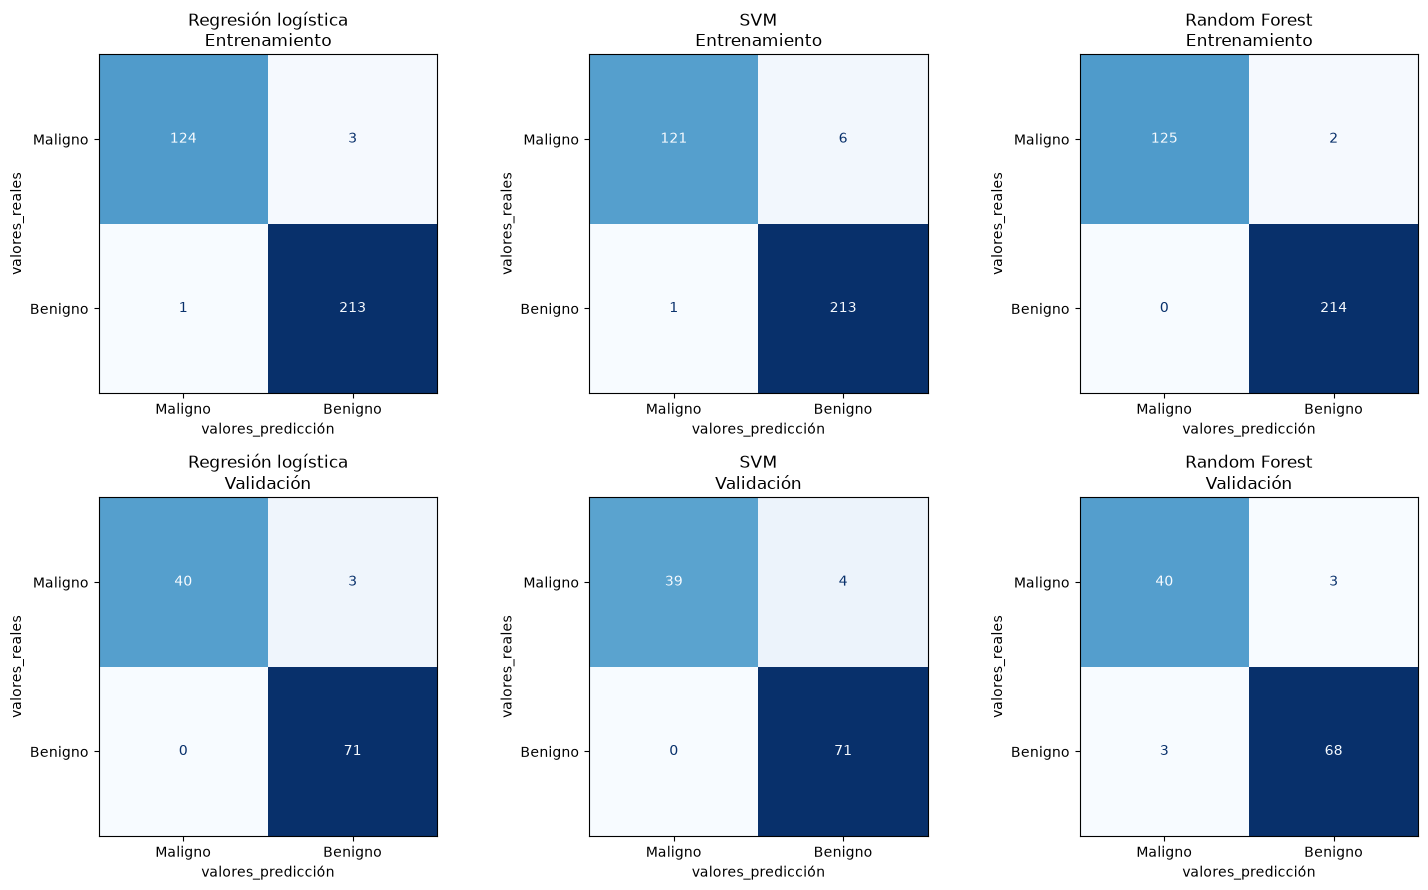

In [77]:
from sklearn.metrics import ConfusionMatrixDisplay

casos = [
    ("Regresión logística", "Entrenamiento", y_train, pred_lr_train),
    ("SVM", "Entrenamiento", y_train, pred_svm_train),
    ("Random Forest", "Entrenamiento", y_train, pred_rf_train),
    ("Regresión logística", "Validación", y_val, pred_lr_val),
    ("SVM", "Validación", y_val, pred_svm_val),
    ("Random Forest", "Validación", y_val, pred_rf_val),
]

plt.figure(figsize=(15, 9))
numero = 1

for modelo, conjunto, y_real, y_pred in casos:
    ejes = plt.subplot(2, 3, numero)
    ConfusionMatrixDisplay.from_predictions(
        y_real, y_pred,
        display_labels=["Maligno", "Benigno"],
        cmap="Blues",
        colorbar=False,
        ax=ejes
    )
    ejes.set_title(modelo + "\n" + conjunto)
    ejes.set_xlabel("valores_predicción")
    ejes.set_ylabel("valores_reales")
    numero = numero + 1

plt.tight_layout()
plt.show()

En la matriz, las filas son el diagnóstico real y las columnas lo que predijo el modelo. Arriba a la izquierda están los verdaderos positivos (malignos detectados) y abajo a la derecha los verdaderos negativos (benignos bien identificados). Abajo a la izquierda están los falsos positivos: pacientes sanos a los que se les dijo que tenían cáncer, lo que causa un susto y más estudios. Arriba a la derecha están los falsos negativos, que son el error más grave, porque son pacientes con cáncer a los que se les dijo que estaban bien.

En los tres modelos el error más común es el falso negativo. La regresión logística y la SVM no tienen falsos positivos en validación, mientras que el Random Forest tiene tres. El Random Forest es el que más cambia de entrenamiento (2 errores) a validación (6 errores).

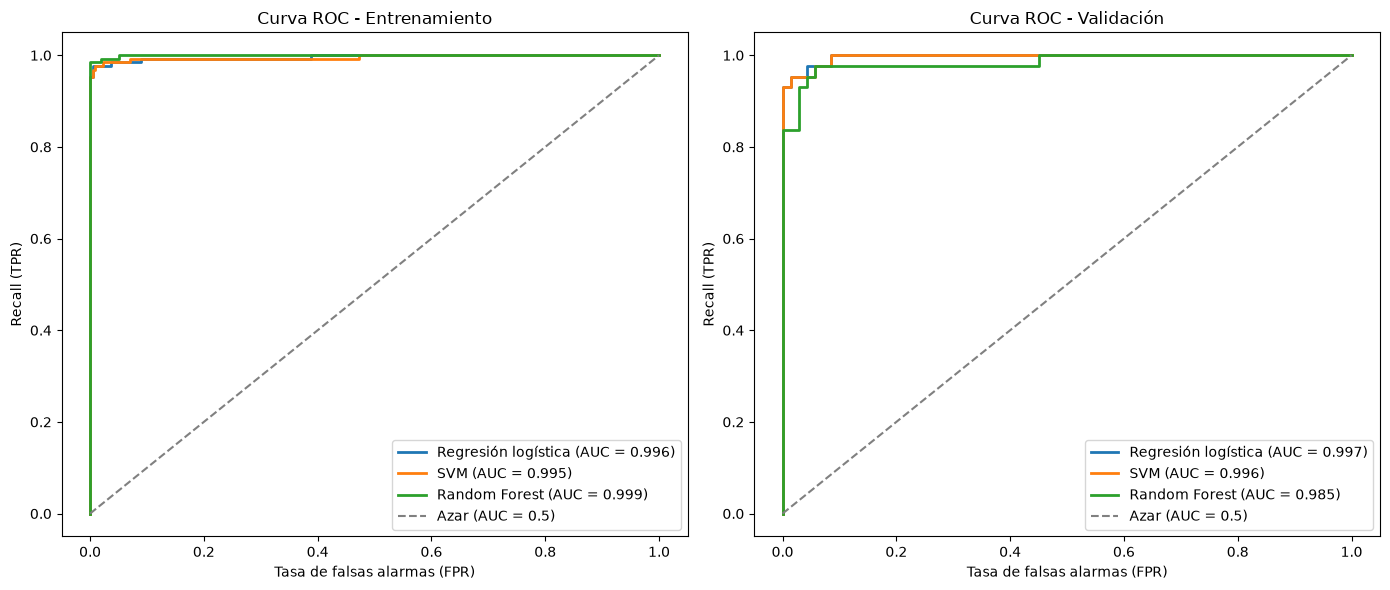

In [78]:
def dibujar_roc(ejes, y_real, puntaje, nombre):
    fpr, tpr, _ = roc_curve(y_real, puntaje, pos_label=0)
    area = auc(fpr, tpr)
    ejes.plot(fpr, tpr, linewidth=2, label=nombre + " (AUC = " + str(round(area, 3)) + ")")


plt.figure(figsize=(14, 6))

# --- Entrenamiento ---
ejes1 = plt.subplot(1, 2, 1)
dibujar_roc(ejes1, y_train, punt_lr_train, "Regresión logística")
dibujar_roc(ejes1, y_train, punt_svm_train, "SVM")
dibujar_roc(ejes1, y_train, punt_rf_train, "Random Forest")
ejes1.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ejes1.set_title("Curva ROC - Entrenamiento")
ejes1.set_xlabel("Tasa de falsas alarmas (FPR)")
ejes1.set_ylabel("Recall (TPR)")
ejes1.legend()

# --- Validación ---
ejes2 = plt.subplot(1, 2, 2)
dibujar_roc(ejes2, y_val, punt_lr_val, "Regresión logística")
dibujar_roc(ejes2, y_val, punt_svm_val, "SVM")
dibujar_roc(ejes2, y_val, punt_rf_val, "Random Forest")
ejes2.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ejes2.set_title("Curva ROC - Validación")
ejes2.set_xlabel("Tasa de falsas alarmas (FPR)")
ejes2.set_ylabel("Recall (TPR)")
ejes2.legend()

plt.tight_layout()
plt.show()

En entrenamiento las tres curvas están pegadas a la esquina. En validación, las de la regresión logística y la SVM (que casi se enciman) llegan a detectar todos los malignos con una tasa de falsas alarmas de apenas 0.08. Eso quiere decir que los malignos que se les escaparon sí tenían una sospecha alta, solo que no pasaron del 0.5; si se bajara el umbral se detectarían con pocas falsas alarmas extra. El Random Forest necesita llegar a 0.45 de falsas alarmas para detectar todos, porque a uno de los malignos le dio muy poca sospecha, y por eso su AUC es el más bajo.

## 6. ¿Hay overfitting o underfitting?

El underfitting (subajuste) es cuando el modelo es demasiado simple y no aprende los patrones, así que le va mal tanto en entrenamiento como en validación; se relaciona con un sesgo alto. El overfitting (sobreajuste) es cuando el modelo memoriza los datos de entrenamiento, así que le va muy bien ahí pero bastante peor en validación; se relaciona con una varianza alta. Para detectarlos se comparan las métricas de los dos conjuntos.

La regularización sirve justamente para frenar el sobreajuste, limitando qué tan complejo puede volverse el modelo. En este proyecto eso lo hicieron C en la regresión logística y la SVM, y la profundidad y el tamaño de las hojas en el Random Forest.

En la siguiente tabla se resta validación a entrenamiento: si la diferencia es cercana a 0, el modelo generaliza bien.

In [79]:
metricas = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

entren = tabla_comparativa[tabla_comparativa["Conjunto"] == "Entrenamiento"].set_index("Modelo")
valid = tabla_comparativa[tabla_comparativa["Conjunto"] == "Validación"].set_index("Modelo")

diferencias = (entren[metricas] - valid[metricas]).round(3)
diferencias

,Accuracy,Precision,Recall,F1,AUC
Modelo,,,,,
Regresión logística,0.014,-0.008,0.046,0.020,-0.001
SVM,0.014,-0.008,0.046,0.021,-0.001
Random Forest,0.047,0.070,0.054,0.062,0.014


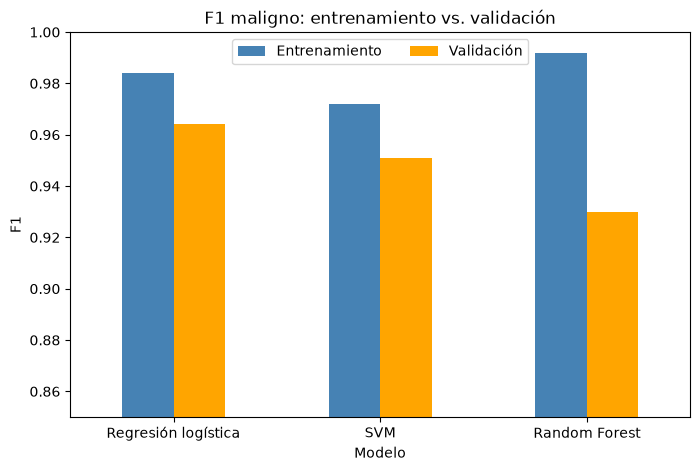

In [81]:
comparacion_f1 = pd.DataFrame({
    "Entrenamiento": entren["F1"],
    "Validación": valid["F1"]
})

comparacion_f1.plot(kind="bar", rot=0, color=["steelblue", "orange"], figsize=(8, 5))
plt.title("F1 maligno: entrenamiento vs. validación")
plt.ylabel("F1")
plt.ylim(0.85, 1.0)
plt.legend(loc="upper center", ncol=2)
plt.show()

Ningún modelo tiene subajuste, porque todos pasan de 0.95 en entrenamiento.

La regresión logística y la SVM no muestran sobreajuste. Sus diferencias en accuracy y F1 son de 1 a 2 puntos y el AUC es prácticamente el mismo en ambos conjuntos. La diferencia más grande está en el recall (4.6 puntos), pero en validación eso equivale a unos dos pacientes, así que se atribuye al tamaño pequeño del conjunto. Los valores negativos en precisión solo indican que en validación les fue un poco mejor.

El Random Forest sí muestra un sobreajuste leve. Tiene las diferencias más grandes en todas las métricas (de 5 a 7 puntos) y al mismo tiempo es el que peor sale en validación. En la gráfica se ve claro: es el que tiene la barra de entrenamiento más alta y la de validación más baja. El ajuste de hiperparámetros redujo esa diferencia, pero no la quitó del todo.

## 7. Selección del modelo final y evaluación en prueba

La métrica que más importa en este problema es el recall de los malignos. Equivocarse con un maligno y decirle al paciente que está bien puede retrasar su tratamiento, mientras que una falsa alarma se corrige con más estudios. Aun así, no se puede ver solo el recall, porque se puede tener recall perfecto diciendo "maligno" a todos; por eso para el ajuste se usó el F1, y el AUC sirvió como apoyo porque no depende del umbral.

Tampoco basta con el accuracy, porque trata igual los dos errores y puede verse bien aunque el modelo falle con la clase menos común. Aquí, decir siempre "benigno" daría 63 % de accuracy sin detectar un solo cáncer, y si las clases estuvieran todavía más desbalanceadas (por ejemplo 99 % contra 1 %), ese modelo inútil tendría 99 %.

Se eligió la regresión logística con C = 0.1. Fue la mejor o empató en todo: tiene el recall más alto (empatado con el Random Forest), cero falsas alarmas, el mejor F1, el mejor AUC, el mejor resultado en validación cruzada y no tiene sobreajuste. Además fue la mejor en todas las etapas, no solo en una.

Cuando dos modelos dan resultados muy parecidos, conviene quedarse con el más sencillo: es más fácil de explicar, sus coeficientes dicen qué variables pesan más, da probabilidades que le sirven a un médico y es menos probable que memorice. Que haya ganado un modelo lineal cuadra con lo que se vio en la exploración: las clases se separan casi con una línea recta.

Ahora sí, el modelo se evalúa una sola vez con el conjunto de prueba.

In [82]:
pred_test = modelo_lr_aj.predict(X_test)
punt_test = modelo_lr_aj.predict_proba(X_test)[:, 0]

resultado_prueba = pd.DataFrame([
    evaluar("Regresión logística", "Prueba", y_test, pred_test, punt_test)
]).round(3)

resultado_prueba

,Modelo,Conjunto,Accuracy,Precision,Recall,F1,AUC
0,Regresión logística,Prueba,0.974,0.976,0.952,0.964,0.996


In [83]:
lr_tres_conjuntos = pd.concat([
    tabla_comparativa[tabla_comparativa["Modelo"] == "Regresión logística"],
    resultado_prueba
])

lr_tres_conjuntos

,Modelo,Conjunto,Accuracy,Precision,Recall,F1,AUC
0,Regresión logística,Entrenamiento,0.988,0.992,0.976,0.984,0.996
1,Regresión logística,Validación,0.974,1.000,0.930,0.964,0.997
0,Regresión logística,Prueba,0.974,0.976,0.952,0.964,0.996


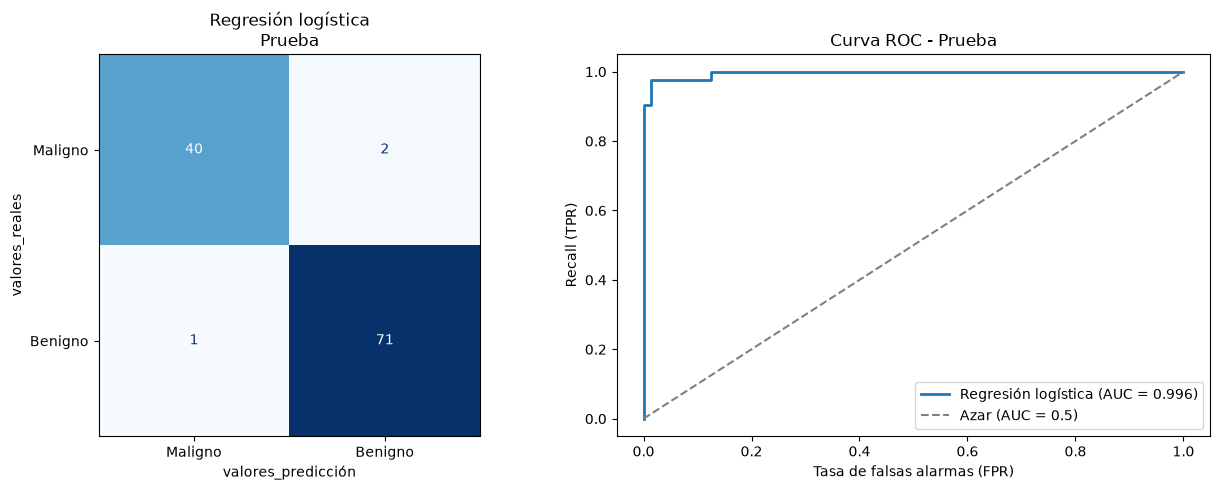

In [84]:
plt.figure(figsize=(13, 5))

# Matriz de confusión
ejes1 = plt.subplot(1, 2, 1)
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test,
    display_labels=["Maligno", "Benigno"],
    cmap="Blues",
    colorbar=False,
    ax=ejes1
)
ejes1.set_title("Regresión logística\nPrueba")
ejes1.set_xlabel("valores_predicción")
ejes1.set_ylabel("valores_reales")

# Curva ROC
ejes2 = plt.subplot(1, 2, 2)
dibujar_roc(ejes2, y_test, punt_test, "Regresión logística")
ejes2.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ejes2.set_title("Curva ROC - Prueba")
ejes2.set_xlabel("Tasa de falsas alarmas (FPR)")
ejes2.set_ylabel("Recall (TPR)")
ejes2.legend(loc="lower right")

plt.tight_layout()
plt.show()

En prueba hay 42 malignos y 72 benignos. El modelo detectó 40 de los 42 malignos y solo dio una falsa alarma, con accuracy de 0.974, precisión de 0.976, recall de 0.952, F1 de 0.964 y AUC de 0.996.

Estos resultados son prácticamente iguales a los de validación (mismo accuracy y F1, y AUC casi igual), así que el modelo funciona igual de bien con pacientes que nunca vio y la estimación de validación era confiable. Las pequeñas diferencias en recall y precisión son de un solo paciente.

## 8. Conclusiones

De los tres modelos, la regresión logística con C = 0.1 fue la que mejor funcionó, y en prueba detectó el 95 % de los tumores malignos con un AUC de 0.996. Un modelo sencillo le ganó a modelos más complejos porque los datos se separan casi de forma lineal, así que la SVM y el Random Forest no tenían mucho que aportar, y el Random Forest incluso mostró algo de sobreajuste. Las variables que más ayudan a distinguir son las de tamaño y concavidad del núcleo, algo que se vio tanto en los boxplots como en la importancia del Random Forest.

Sobre el umbral de decisión: el modelo dice "maligno" cuando la probabilidad pasa de 0.5. Si se baja ese umbral, el modelo marca más casos como malignos, así que sube el recall pero baja la precisión porque aparecen más falsas alarmas; si se sube, pasa lo contrario. Según la curva ROC, bajar un poco el umbral permitiría atrapar los dos malignos que se escaparon en prueba a cambio de pocas falsas alarmas, lo que en un contexto médico podría valer la pena. Ese umbral tendría que elegirse con validación, no con prueba.

Con más tiempo se podría ajustar ese umbral, usar validación cruzada repetida para tener estimaciones más estables con tan pocos datos, quitar variables redundantes como radio, perímetro y área, probar otros modelos como gradient boosting, revisar uno por uno los casos mal clasificados y, sobre todo, probar el modelo con datos de otros hospitales antes de pensar en usarlo en la vida real.